# 04 Residual validation

Is the physics residual (observed minus predicted decay) trustworthy before we run it on the
whole cohort? Data: the two rocket bodies of notebook 03 (NORAD 10114, ~485 km, 97.5 deg;
41341, ~495 km, 30.6 deg), Apr 2024 - Apr 2025, all 20 storms of the catalog.

Steps (task list in `docs/PLAN.md`, residual validation):
1. Hampel (rolling-median) outlier filter on the decay intervals, share removed.
2. Held-out quiet residual: drag sensitivity fitted on half of the quiet intervals, the
   other half must average ~0 (weekly-block SE). If not, stop: drag sensitivity needs fixing.
3. TLE-blur check: smooth the MSIS prediction over 1, 2, 3 days and test a time lag.
   Does the post-storm over-prediction (days 0..+3) survive?
4. `Y_total`: observed minus MSIS 2.1 run with the storm's quiet ap (median ap over days
   -10..-3), actual F10.7 kept.
5. Baseline-relative residual (mean of days 0..+3 minus mean of days -10..-3) for each of
   the 20 storms, NRLMSISE-00 and MSIS 2.1, with and without May and Oct 2024.
6. Verdict with the decision rules of `docs/PLAN.md`.

Sign convention: residual = observed - predicted, both negative (km/day of shrinking `a`).
Residual < 0 = more decay than predicted. A positive baseline-relative change after a storm
= the model over-predicts the decay compared with its own pre-storm error.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.spacetrack_io import download_tle_history
from src.orbit import tles_to_frame, drop_duplicate_epochs, decay_rates
from src.storms import load_storms
from src import physics
from src.plots import plot_outliers, plot_smoothing_zoom, plot_storm_changes

RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:.3g}")

OBJECTS = {10114: "SL-3 R/B (~485 km, 97.5 deg)", 41341: "H-2A R/B (~495 km, 30.6 deg)"}
MODELS = {"nrlmsise00": "NRLMSISE-00", "msis21": "MSIS 2.1"}
EXTREME = {4: "May 2024", 11: "Oct 2024"}      # storm_id of the extreme / severe storms we single out

In [2]:
records = download_tle_history(list(OBJECTS), "2024-04-01", "2025-04-30",
                               out_name="tle_rocketbodies_2024_2025.json")
tles = drop_duplicate_epochs(tles_to_frame(records))
rates = decay_rates(tles)
sw = physics.load_msis_weather()
storms = load_storms()
out = physics.run_physics(tles, rates, sw, storms)
print(f"{len(out)} decay intervals; quiet ap per storm (median ap, days -10..-3):")
print(physics.quiet_ap(sw, storms).round(1).to_dict())

1694 decay intervals; quiet ap per storm (median ap, days -10..-3):
{1: 5.0, 2: 9.0, 3: 5.0, 4: 6.0, 5: 5.0, 6: 7.0, 7: 6.0, 8: 7.0, 9: 6.0, 10: 18.0, 11: 6.0, 12: 9.0, 13: 5.0, 14: 7.0, 15: 18.0, 16: 12.0, 17: 12.0, 18: 9.0, 19: 22.0, 20: 18.0}


## 1. Hampel outlier filter

The filter runs per object on the MSIS 2.1 residual, not on the observed decay: the observed
decay jumps at every storm and a rolling median would throw out the real storm response.
Window: 5 days centred (time-based, the TLE spacing is irregular, ~12 intervals per window);
an interval is an outlier if it is more than 3.5 robust SDs (3.5 x 1.4826 x MAD) from the
rolling median. B and the predictions of both models are refitted without the outliers.
The table below the plots shows why not a shorter window: with ~7 points the MAD itself is
noisy and the filter flags several percent of pure normal noise.

In [3]:
flagged = physics.flag_outliers(out)
clean, report = physics.remove_outliers(out)
print(f"Removed {flagged['outlier'].sum()} of {len(out)} intervals ({flagged['outlier'].mean():.1%})")
report

Removed 71 of 1694 intervals (4.2%)


,norad_id,role,removed,intervals,share
0,10114,fit,8,268,0.0299
1,10114,holdout,8,268,0.0299
2,10114,storm,23,427,0.0539
3,41341,fit,11,212,0.0519
4,41341,holdout,6,211,0.0284
5,41341,storm,15,308,0.0487


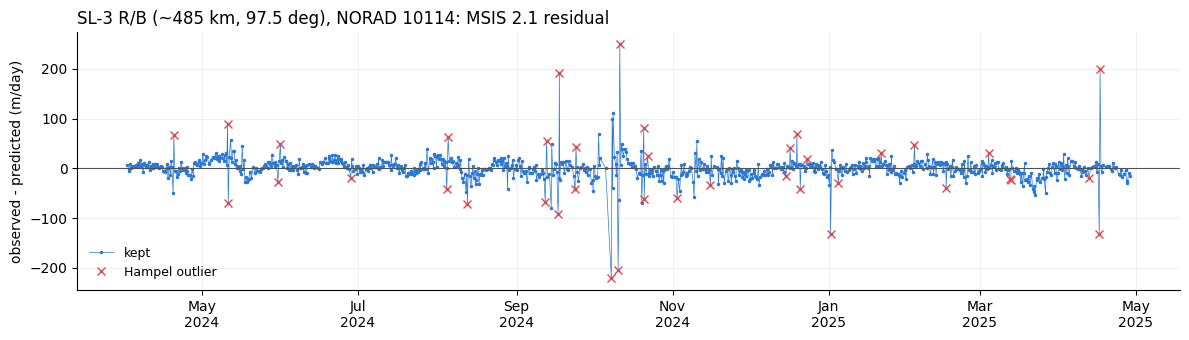

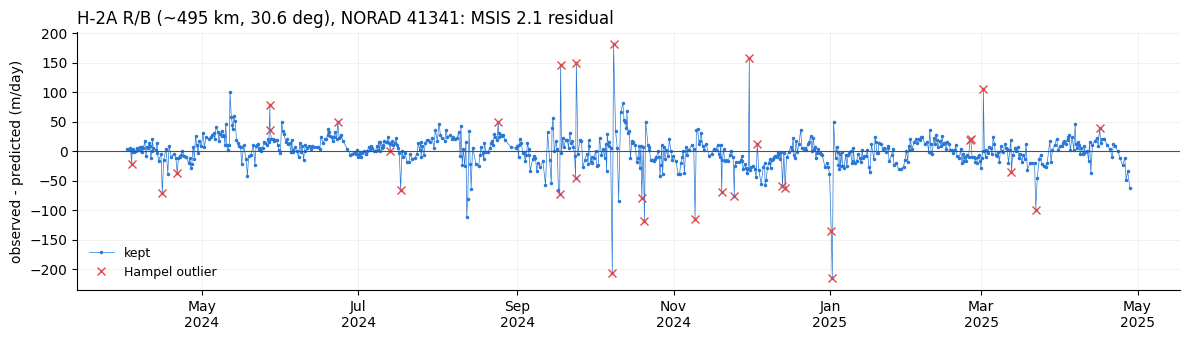

In [4]:
for norad_id, name in OBJECTS.items():
    g = flagged[flagged["norad_id"] == norad_id]
    plot_outliers(g, g["outlier"].to_numpy(), "msis21", f"{name}, NORAD {norad_id}: MSIS 2.1 residual",
                  out_path=RESULTS / f"residval_outliers_{norad_id}.png")

In [5]:
# Sensitivity: share flagged on the real residuals vs on pure normal noise with the same spacing
rng = np.random.default_rng(0)
rows = []
for window in ("3D", "5D", "7D"):
    for k in (3.0, 3.5):
        f = physics.flag_outliers(out, window=window, k=k)
        noise = []
        for _ in range(20):
            t = pd.Timestamp("2024-06-01") + pd.to_timedelta(np.cumsum(rng.uniform(0.2, 0.6, 300)), unit="D")
            noise.append(physics.hampel_flags(rng.normal(size=300), t, window=window, k=k).mean())
        rows.append({"window": window, "k": k, "real: all": f["outlier"].mean(),
                     "real: quiet": f.loc[f["role"] != "storm", "outlier"].mean(),
                     "real: storm": f.loc[f["role"] == "storm", "outlier"].mean(),
                     "normal noise": np.mean(noise)})
pd.DataFrame(rows)

,window,k,real: all,real: quiet,real: storm,normal noise
0,3D,3,0.0555,0.0521,0.0599,0.0375
1,3D,3.5,0.046,0.0428,0.0503,0.0282
2,5D,3,0.0537,0.0448,0.0653,0.0272
3,5D,3.5,0.0419,0.0344,0.0517,0.00883
4,7D,3,0.0573,0.0459,0.0721,0.0172
5,7D,3.5,0.0431,0.0334,0.0558,0.008


## 2. Held-out quiet residual

Quiet intervals (no overlap with any storm from 3 days before onset to 3 days after
recovery) alternate between 'fit' and 'holdout'. B = sum(observed * dt) / sum(driver * dt)
on the fit intervals. The holdout mean must be ~0: within 2 weekly-block SEs.

B used to be the median of observed / driver. After outlier removal that left 41341 with a
held-out MSIS 2.1 residual of -4.6 m/day (t = -2.2): the median weights short, noisy intervals
as much as long ones and came out ~3% low. The comparison below shows both estimators.

In [6]:
hold = pd.concat([physics.holdout_residual(clean, m) for m in MODELS])
hold[["mean_resid", "se_naive", "se_block"]] *= 1000          # m/day
hold["t_block"] = hold["mean_resid"] / hold["se_block"]
hold["ok (|t| < 2)"] = hold["t_block"].abs() < 2
B = pd.DataFrame({MODELS[m]: physics.fit_drag_sensitivity(clean, m) for m in MODELS})
print("drag sensitivity B (m^2/kg):"); print(B)
assert hold["ok (|t| < 2)"].all(), "Held-out quiet residual is not ~0: fix drag sensitivity first"
hold

drag sensitivity B (m^2/kg):
          NRLMSISE-00  MSIS 2.1
norad_id                       
10114         0.00895    0.0101
41341          0.0156    0.0178


,norad_id,model,mean_resid,se_naive,se_block,n,t_block,ok (|t| < 2)
0,10114,nrlmsise00,0.392,0.863,1.78,260,0.22,True
1,41341,nrlmsise00,-1.32,1.28,2.54,205,-0.52,True
0,10114,msis21,0.196,0.821,1.63,260,0.12,True
1,41341,msis21,-1.01,1.13,1.96,205,-0.513,True


In [7]:
# Old estimator (median of observed / driver) vs the ratio of sums, same filtered intervals
rows = []
for m, label in MODELS.items():
    fit = clean[clean["role"] == "fit"]
    B_med = (fit["da_dt_km_per_day"] / fit[f"driver_{m}"]).groupby(fit["norad_id"]).median()
    for name, B_m in (("median of ratios", B_med), ("ratio of sums", physics.fit_drag_sensitivity(clean, m))):
        h = physics.holdout_residual(physics.add_predictions(clean, m, B=B_m), m)
        for _, r in h.iterrows():
            rows.append({"model": label, "estimator": name, "norad_id": r["norad_id"], "B": B_m[r["norad_id"]],
                         "holdout mean (m/day)": 1000 * r["mean_resid"], "t_block": r["mean_resid"] / r["se_block"]})
pd.DataFrame(rows).set_index(["model", "norad_id", "estimator"]).sort_index()

B  holdout mean (m/day)  t_block
model       norad_id estimator                                              
MSIS 2.1    10114    median of ratios  0.0099                 -1.44   -0.871
                     ratio of sums     0.0101                 0.196     0.12
            41341    median of ratios  0.0173                 -4.55    -2.23
                     ratio of sums     0.0178                 -1.01   -0.513
NRLMSISE-00 10114    median of ratios 0.00878                  -1.2   -0.666
                     ratio of sums    0.00895                 0.392     0.22
            41341    median of ratios  0.0154                 -2.83    -1.11
                     ratio of sums     0.0156                 -1.32    -0.52

## 3. `Y_total`: prediction with the storm's quiet ap

MSIS 2.1 rerun with all ap inputs set to the storm's quiet ap (median over days -10..-3),
actual F10.7 kept, same B. `Y_total = observed - B * driver_quiet` (m/day): the total
extra decay caused by the storm, separated from Sun UV. Intervals outside every event
window keep the actual ap.

In [8]:
q = physics.quiet_ap_drivers(tles, rates, sw, storms)
clean = clean.merge(q[["norad_id", "t_start", "storm_id", "quiet_ap", "driver_quiet_msis21"]],
                    on=["norad_id", "t_start"], how="left")
clean = physics.add_total_effect(clean)
clean["Y_total"] = clean["total_msis21"] * 1000
clean["Y_residual"] = clean["resid_msis21"] * 1000
win = clean[clean["storm_id"].isin(list(EXTREME))]
win.groupby(["storm_id", "norad_id"])[["Y_residual", "Y_total"]].agg(["mean", "min"])

Y_residual       Y_total      
                        mean   min    mean   min
storm_id norad_id                               
4        10114          7.68 -27.1    1.43 -68.4
         41341          16.6 -41.9     2.2  -131
11       10114          4.01 -69.6   -5.37  -147
         41341          5.64 -84.4   -5.48  -119

## 4. TLE-blur check

A TLE is fitted to several days of tracking, so the observed decay is a blurred version of
the true decay, while MSIS responds within hours. We smooth the predicted decay with a
centred, time-weighted 1, 2 and 3 day window (B refitted each time) and also shift it by
the lag that best matches the observed decay.

best lag: -3 h (correlation {10114: 0.851, 41341: 0.901}, at 0 h {10114: 0.846, 41341: 0.897})


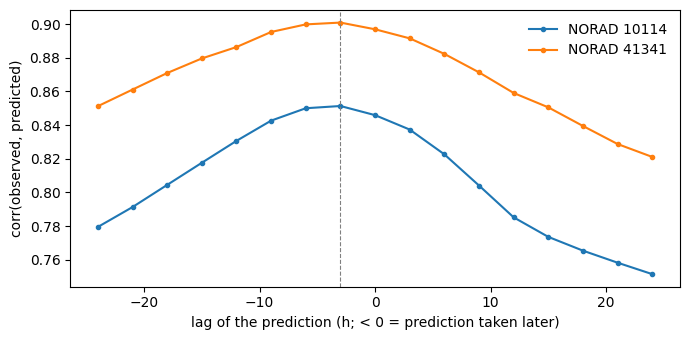

In [9]:
lags = physics.lag_correlation(clean, "msis21", lags=range(-24, 25, 3))
best = int(lags.mean(axis=1).idxmax())
fig, ax = plt.subplots(figsize=(7, 3.5))
for nid in lags:
    ax.plot(lags.index, lags[nid], marker="o", ms=3, label=f"NORAD {nid}")
ax.axvline(best, color="gray", lw=0.8, ls="--")
ax.set_xlabel("lag of the prediction (h; < 0 = prediction taken later)")
ax.set_ylabel("corr(observed, predicted)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(RESULTS / "residval_lag_correlation.png", dpi=150)
print(f"best lag: {best} h (correlation {lags.loc[best].round(3).to_dict()}, at 0 h {lags.loc[0].round(3).to_dict()})")

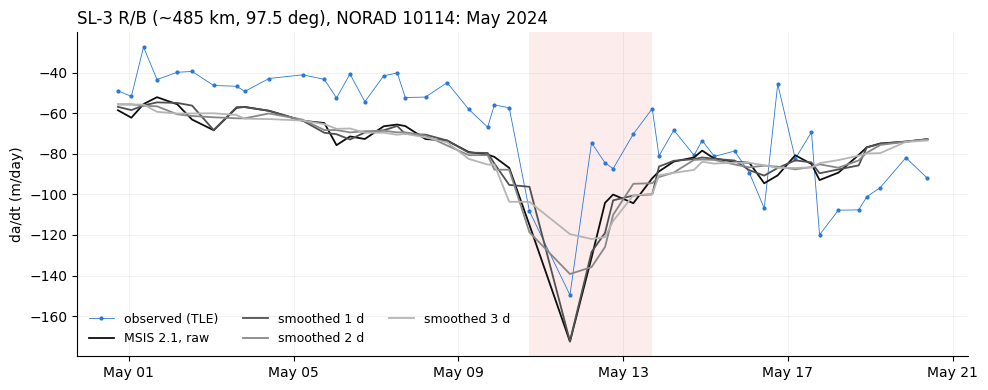

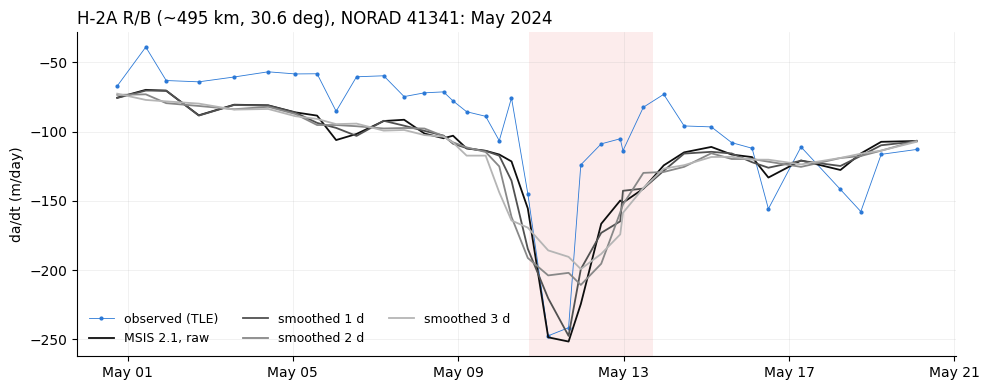

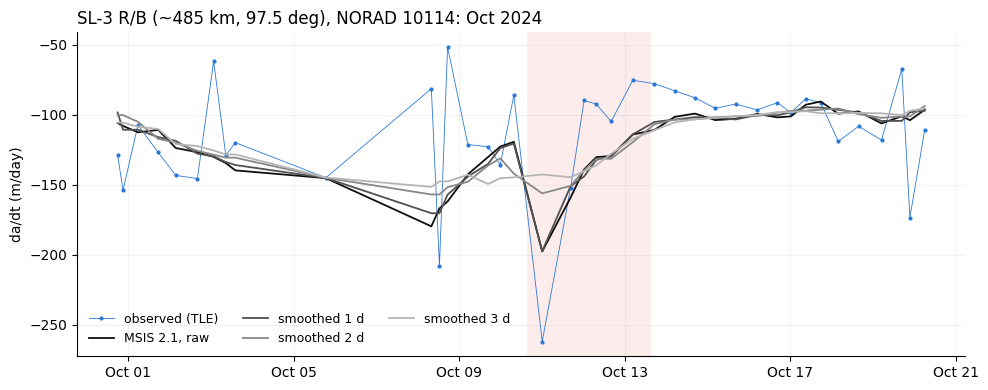

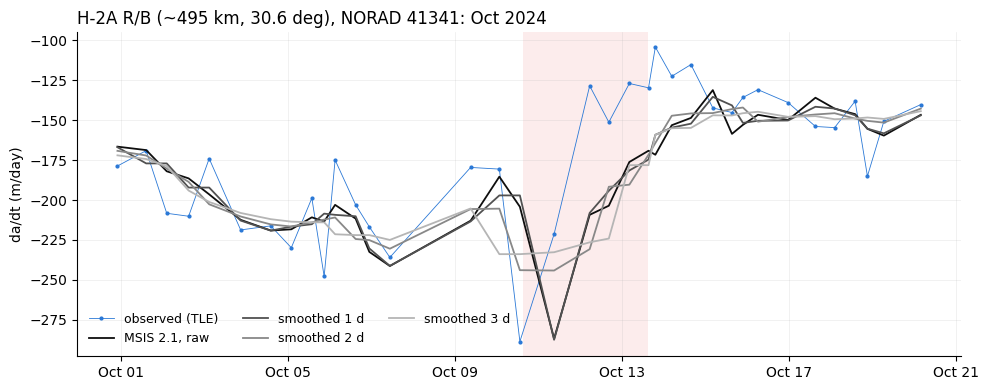

In [10]:
variants = {"msis21": "MSIS 2.1, raw"}
for d in (1, 2, 3):
    clean = physics.smooth_driver(clean, "msis21", d)
    clean = physics.add_predictions(clean, f"msis21_s{d}")
    variants[f"msis21_s{d}"] = f"smoothed {d} d"
clean = physics.shift_driver(clean, "msis21", best)
clean = physics.add_predictions(clean, f"msis21_lag{best:g}")
variants[f"msis21_lag{best:g}"] = f"lag {best} h"

for sid, event in EXTREME.items():
    t0 = storms.set_index("storm_id").loc[sid, "main_onset"]
    for nid, name in OBJECTS.items():
        plot_smoothing_zoom(clean[clean["norad_id"] == nid], {k: v for k, v in variants.items() if "lag" not in k},
                            t0, f"{name}, NORAD {nid}: {event}",
                            out_path=RESULTS / f"residval_smoothing_{event.replace(' ', '_')}_{nid}.png")

## 5. Baseline-relative residual for all 20 storms

Per storm and object: time-weighted mean residual over days 0..+3 minus the mean over days
-10..-3 (intervals that bridge `main_onset` dropped). Objects are averaged within a storm,
then the mean over storms gets an SE across storms (storm = cluster) and a t interval.

In [11]:
columns = {"resid_nrlmsise00": "NRLMSISE-00", "resid_msis21": "MSIS 2.1",
           **{f"resid_{k}": v for k, v in variants.items() if k != "msis21"},
           "total_msis21": "Y_total (MSIS 2.1, quiet ap)"}
per_storm, rows = {}, []
for col, label in columns.items():
    ps = physics.storm_baseline_residual(clean, storms, col)
    ps[["pre", "post", "change", "se"]] *= 1000                    # m/day
    per_storm[label] = ps
    for sample, excl in (("all 20 storms", ()), ("without May/Oct 2024", tuple(EXTREME))):
        rows.append({"outcome": label, "sample": sample, **physics.storm_mean(ps, exclude=excl)})
summary = pd.DataFrame(rows).set_index(["outcome", "sample"])
summary

mean   se  ci_lo  ci_hi  storms  positive
outcome                      sample                                                            
NRLMSISE-00                  all 20 storms            4.86 4.18  -3.88   13.6      20        13
                             without May/Oct 2024     2.03 3.98  -6.36   10.4      18        11
MSIS 2.1                     all 20 storms            4.04 4.21  -4.76   12.8      20        13
                             without May/Oct 2024     1.21 4.03  -7.29    9.7      18        11
smoothed 1 d                 all 20 storms            3.63 4.16  -5.07   12.3      20        12
                             without May/Oct 2024    0.929 3.98  -7.48   9.33      18        10
smoothed 2 d                 all 20 storms            2.18 4.05   -6.3   10.7      20        12
                             without May/Oct 2024 0.000435 4.04  -8.53   8.53      18        10
smoothed 3 d                 all 20 storms           0.697 4.02  -7.72   9.12      20        12
                             without May/Oct 2024    -1.16  4.1   -9.8   7.48      18        10
lag -3 h                     all 20 storms            2.62 4.04  -5.84   11.1      20        12
                             without May/Oct 2024    0.263 4.01  -8.19   8.72      18        10
Y_total (MSIS 2.1, quiet ap) all 20 storms           -8.17 4.46  -17.5   1.17      20         7
                             without May/Oct 2024     -6.7 4.64  -16.5   3.08      18         7

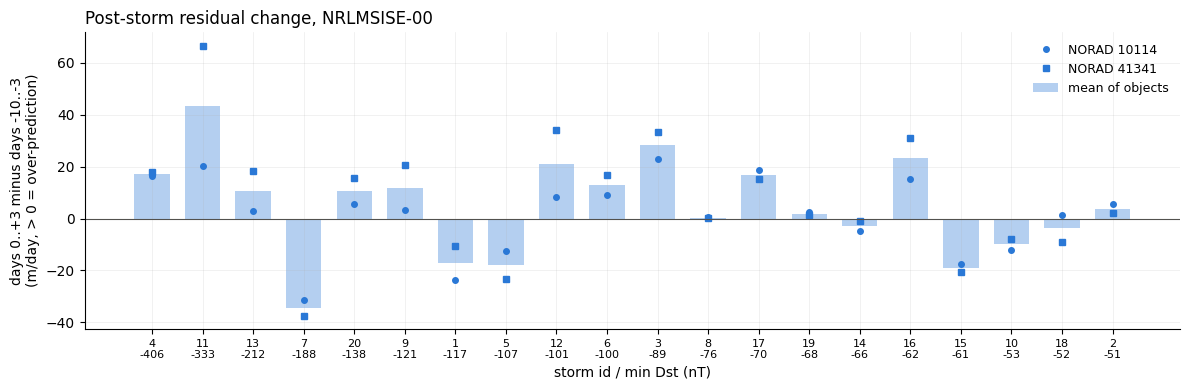

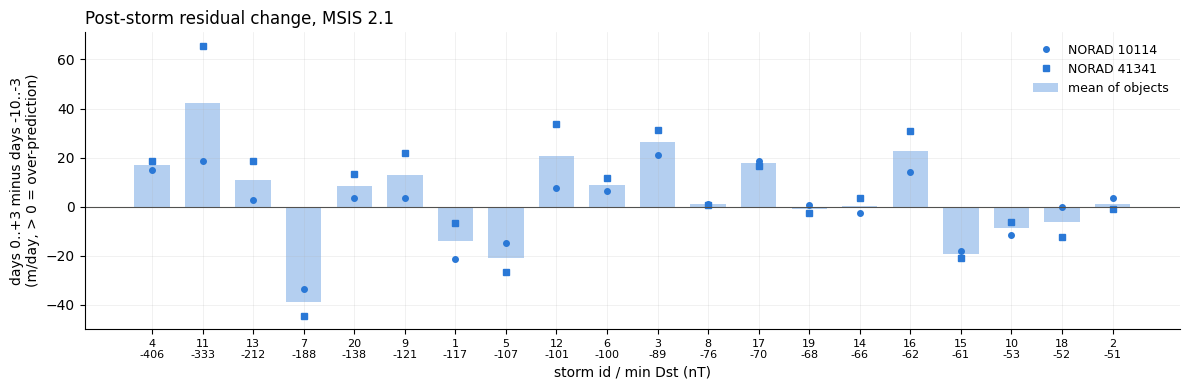

In [12]:
for label in ("NRLMSISE-00", "MSIS 2.1"):
    key = label.replace(" ", "").replace(".", "").replace("-", "").lower()
    plot_storm_changes(per_storm[label], f"Post-storm residual change, {label}",
                       out_path=RESULTS / f"residval_storms_{key}.png")

In [13]:
rows = []
for label, ps in per_storm.items():
    for _, r in ps[ps["storm_id"].isin(list(EXTREME))].iterrows():
        rows.append({"outcome": label, "storm": EXTREME[r["storm_id"]], "norad_id": r["norad_id"],
                     "change": r["change"], "se": r["se"], "change / se": r["change"] / r["se"],
                     "obs / pred (days 0..3)": r.get("obs_over_pred", np.nan)})
extremes = pd.DataFrame(rows)
extremes.pivot_table(index=["storm", "norad_id"], columns="outcome", values="change", sort=False)

outcome            NRLMSISE-00  MSIS 2.1  smoothed 1 d  smoothed 2 d  smoothed 3 d  lag -3 h  Y_total (MSIS 2.1, quiet ap)
storm    norad_id                                                                                                         
May 2024 10114            16.5      15.1          14.1          8.74           2.6      8.83                         -26.3
         41341            18.1      18.8          13.6          7.14          3.85      14.2                         -51.4
Oct 2024 10114            20.3      18.7          18.7          15.1            12      13.6                         -9.98
         41341            66.6      65.5          65.5          56.2            51      58.5                          2.12

In [14]:
extremes.set_index(["outcome", "storm", "norad_id"]).loc[["MSIS 2.1", "smoothed 3 d"]]

change   se  change / se  obs / pred (days 0..3)
outcome      storm    norad_id                                                  
MSIS 2.1     May 2024 10114       15.1 7.88         1.92                   0.729
                      41341       18.8 12.9         1.46                   0.776
             Oct 2024 10114       18.7 19.7        0.949                   0.873
                      41341       65.5 8.77         7.47                   0.724
smoothed 3 d May 2024 10114        2.6 13.6        0.191                   0.811
                      41341       3.85 23.1        0.167                   0.842
             Oct 2024 10114         12   28        0.429                   0.929
                      41341         51 19.3         2.64                   0.772

## 6. Verdict

Decision rules (`docs/PLAN.md`): survives smoothing -> "models recover too slowly after
storms"; vanishes after smoothing -> TLE blur, switch the outcome to total altitude lost from a
calm day before to a calm day after; only holds with May/Oct -> driven by extreme storms.

In [15]:
label, why = physics.post_storm_verdict(
    summary.loc[("MSIS 2.1", "all 20 storms")],
    summary.loc[("MSIS 2.1", "without May/Oct 2024")],
    summary.loc[("smoothed 3 d", "all 20 storms")],
    extremes[extremes["outcome"] == "smoothed 3 d"])
print(f"Verdict: {label}\n{why}")

Verdict: extreme-storm driven
no over-prediction across the 20 storms (95% interval -4.8 to 12.8); seen only in the extreme storms, where 1 of 4 storm-object pairs survive the strongest smoothing


**Verdict: driven by extreme storms; in May 2024 it is TLE blur. Do not headline "models recover too slowly after storms".**

- **Outlier filter**: the Hampel filter (5-day window, k = 3.5) removes 71 of 1,694 intervals (4.2%);
  on pure normal noise with the same spacing it flags ~1%, so the real residuals have heavy tails.
  Storm intervals lose a little more (5%) than quiet ones (3-4%): storm-time TLEs are noisier.
- **Held-out quiet residual is ~0** with drag sensitivity B = dt-weighted ratio of sums:
  MSIS 2.1 +0.2 m/day (block SE 1.6) for 10114 and -1.0 (2.0) for 41341; NRLMSISE-00 +0.4 (1.8)
  and -1.3 (2.5); all |t| < 0.6. The old median-of-ratios B failed for 41341 (-4.6 m/day, t = -2.2),
  so B was switched (`physics.fit_drag_sensitivity`).
- **Across all 20 storms there is no post-storm over-prediction.** Baseline-relative residual
  (days 0..+3 minus days -10..-3): MSIS 2.1 +4.0 m/day (95% interval -4.8 to 12.8), NRLMSISE-00 +4.9
  (-3.9 to 13.6). Without May/Oct 2024: +1.2 and +2.0. 13 of 20 storms are positive.
- **The over-prediction is in the extreme storms**: May 2024 +15 / +19 m/day, Oct 2024 +19 / +66 m/day
  (obs/pred 0.72-0.87 in days 0..+3). By the decision rule it is **extreme-storm driven**.
- **TLE-blur check on those storms**: with the prediction smoothed over 3 days, May drops to +3 / +4
  m/day (well inside its SE), so in May it is **TLE blur**. Oct 2024 for 41341 survives (+51, 2.6 SE);
  10114 is too noisy to tell (+12, SE 28). The best lag between prediction and observation is only
  -3 h (correlation 0.851 vs 0.846 at 0 h) and shifting by it changes little: the models are not
  mistimed by hours, the TLE decay is spread over days.
- **`Y_total`** (observed minus MSIS 2.1 with the storm's quiet ap): baseline-relative change -8.2 m/day
  across the 20 storms (-17.5 to +1.2), -6.7 without May/Oct. The storm adds decay beyond a quiet-day
  atmosphere, but with two objects the interval still includes zero. For Oct 2024 the days -10..-3
  baseline is not quiet: it includes the weaker Oct 6-7 dip merged into the same event.

**What changes:**
1. The headline is not "models recover too slowly". Report the post-storm over-prediction as a
   feature of the extreme storms that is partly TLE blur (May vanishes, Oct 2024 partly survives).
2. For the extreme storms, add the blur-free outcome from the decision rules: total altitude lost
   from a calm day before to a calm day after the storm.
3. Keep `Y_residual` (model error) and `Y_total` (total storm effect) as the two estimands.
   `Y_total` is now in `src/schema.py` as an optional column.
4. Caveat: two objects only. The SE across storms (~4 m/day) means only effects above ~8-9 m/day
   would be detected. Rerun this notebook on the full cohort once A2-A4 is merged.
